## WEEK 10 - START



In [3]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Paths follow the same layout as Weeks 3 to 9
DATA_DIR = Path("../data/processed")
MODEL_DIR = Path("../models")
FIG_DIR = Path("../figures")

TRAIN_PATH = DATA_DIR / "train_model_reduced.csv"
TEST_PATH = DATA_DIR / "test_model_reduced.csv"
MODEL_PATH = MODEL_DIR / "week9_final_model.joblib"

TARGET = "Response"
RANDOM_STATE = 42
VALIDATION_SIZE = 0.20   # share of the training data held out as the validation dataset

# Same cross-validation protocol as Weeks 6 to 9: 5 folds repeated 3 times (15 scores per treatment)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

# The saved Week 9 model was pickled with an older scikit-learn version; the warning is harmless here
warnings.filterwarnings("ignore", message=".*Trying to unpickle estimator.*")

print("Week 10: Data-Centric AI")
print("Training dataset available:", TRAIN_PATH.is_file())
print("Test dataset available:", TEST_PATH.is_file())
print("Week 9 model available:", MODEL_PATH.is_file())
FIG_DIR.mkdir(parents=True, exist_ok=True)

Week 10: Data-Centric AI
Training dataset available: True
Test dataset available: True
Week 9 model available: True


### Load the Week 9 model and the datasets

The Week 9 file stores the winning model together with its list of predictors. Only the model settings and the predictor list are used: the model is refit on the training data below.

In [4]:
# Load the Week 9 winner (model object, predictor names, model name)
week9_model = joblib.load(MODEL_PATH)
final_model = week9_model["model"]
feature_names = week9_model["features"]
model_name = week9_model["name"]

print("Selected Model:", model_name)
print("Model Configuration:", final_model)
print("Number of Predictors:", len(feature_names))

# Load the processed datasets and check that every predictor and the target are present
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

for name, df in [("Training", train_df), ("Test", test_df)]:
    missing = [c for c in feature_names + [TARGET] if c not in df.columns]
    if missing:
        raise ValueError(f"{name} dataset is missing columns: {missing}")

print("Original training dataset:", train_df.shape, "| test dataset:", test_df.shape)

Selected Model: W6 Logistic regression
Model Configuration: LogisticRegression(C=3, max_iter=5000, solver='liblinear')
Number of Predictors: 27
Original training dataset: (1608, 28) | test dataset: (412, 28)


### Create the training and validation datasets

The original training data is split once, stratified on the target so the response rate stays the same in both parts. The validation dataset is not used to fit anything; it only measures how the model and the data treatments generalize before the test set is touched.

In [5]:
# One stratified split with a fixed seed so the datasets are identical on every run
train_fit_df, val_df = train_test_split(
    train_df,
    test_size=VALIDATION_SIZE,
    stratify=train_df[TARGET],
    random_state=RANDOM_STATE,
)
train_fit_df = train_fit_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

X_train, y_train = train_fit_df[feature_names], train_fit_df[TARGET]
X_val, y_val = val_df[feature_names], val_df[TARGET]
X_test, y_test = test_df[feature_names], test_df[TARGET]

split_summary = pd.DataFrame({
    "Customers": [len(X_train), len(X_val), len(X_test)],
    "Responders": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "Response rate": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["Training", "Validation", "Test"])
display(split_summary.round(4))

,Customers,Responders,Response rate
Training,1286,187,0.1454
Validation,322,47,0.1460
Test,412,63,0.1529


### Step 1: Baseline performance on training, validation and test

The Week 9 model settings are refit on the new training dataset. Every dataset is scored with the same metrics. **Top-40% capture** is the share of responders found among the 40% of customers with the highest predicted probability, which is how the campaign would use the model.

In [6]:
def top_share_capture(y_true, proba, share=0.40):
    # Share of all responders found in the top `share` of customers ranked by predicted probability
    y_true = np.asarray(y_true)
    n_top = int(np.ceil(share * len(y_true)))
    order = np.argsort(-np.asarray(proba))
    return y_true[order][:n_top].sum() / y_true.sum()


def score_dataset(model, X, y):
    # All metrics for one dataset; precision, recall and F1 use the 0.5 probability cutoff as in earlier weeks
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        "PR-AUC": average_precision_score(y, proba),
        "ROC-AUC": roc_auc_score(y, proba),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Log loss": log_loss(y, proba),
        "Top-40% capture": top_share_capture(y, proba),
    }


baseline_model = clone(final_model).fit(X_train, y_train)

baseline_table = pd.DataFrame({
    "Training": score_dataset(baseline_model, X_train, y_train),
    "Validation": score_dataset(baseline_model, X_val, y_val),
    "Test": score_dataset(baseline_model, X_test, y_test),
})
display(baseline_table.round(4))

# Reference: the Week 9 model as saved was fit on all 1,608 original training customers
week9_test = score_dataset(final_model, X_test, y_test)
print("Reference, Week 9 saved model on the test set: PR-AUC =", round(week9_test["PR-AUC"], 4))

,Training,Validation,Test
PR-AUC,0.7664,0.7300,0.6461
ROC-AUC,0.9445,0.9079,0.8840
Precision,0.7810,0.7500,0.7179
Recall,0.5722,0.5106,0.4444
F1,0.6605,0.6076,0.5490
Log loss,0.2041,0.2373,0.2847
Top-40% capture,0.9679,0.9149,0.8571


Reference, Week 9 saved model on the test set: PR-AUC = 0.6653


## Step 2: Error analysis on the training data

Predictions for every training customer are made by models that never saw that customer (5-fold cross-validation, "out-of-fold" predictions). Errors measured this way are honest: they are not hidden by the model having memorized its own training data. The analysis answers three questions:

1. Which customers does the model miss or wrongly flag?
2. Where in the data (which kinds of customers) are the errors concentrated?
3. Are there data quality problems that could be causing errors?

In [7]:
# Out-of-fold probabilities for every training customer
oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_proba = cross_val_predict(
    clone(final_model), X_train, y_train, cv=oof_cv, method="predict_proba"
)[:, 1]
oof_pred = (oof_proba >= 0.5).astype(int)

# Confusion matrix at the 0.5 cutoff
tn, fp, fn, tp = confusion_matrix(y_train, oof_pred).ravel()
confusion = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual: no response", "Actual: response"],
    columns=["Predicted: no response", "Predicted: response"],
)
display(confusion)
print(f"Responders found at the 0.5 cutoff: {tp} of {tp + fn} ({tp / (tp + fn):.1%})")
print(f"Responders missed (false negatives): {fn}")
print(f"Customers flagged who did not respond (false positives): {fp}")

# Label each training customer by outcome so error groups can be compared
y_arr = y_train.to_numpy()
error_group = np.select(
    [(y_arr == 1) & (oof_pred == 1), (y_arr == 1) & (oof_pred == 0), (y_arr == 0) & (oof_pred == 1)],
    ["TP", "FN", "FP"],
    default="TN",
)
error_df = X_train.copy()
error_df["error_group"] = error_group
error_df["oof_proba"] = oof_proba
error_df[TARGET] = y_arr
print(error_df["error_group"].value_counts().to_string())

,Predicted: no response,Predicted: response
Actual: no response,1058,41
Actual: response,86,101


Responders found at the 0.5 cutoff: 101 of 187 (54.0%)
Responders missed (false negatives): 86
Customers flagged who did not respond (false positives): 41
error_group
TN    1058
TP     101
FN      86
FP      41


#### Who is missed, and who is wrongly flagged?

Each feature is compared between two groups using the **standardized mean difference** (difference in means divided by the pooled standard deviation). A large value means that feature separates the groups.

- **Missed responders (FN) vs found responders (TP):** what makes some responders hard to find.
- **False alarms (FP) vs correct non-responders (TN):** what makes some non-responders look like responders.

In [8]:
def standardized_mean_difference(a, b):
    # (mean a - mean b) / pooled standard deviation; 0 when both groups have no spread
    pooled = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return 0.0 if pooled == 0 or np.isnan(pooled) else (a.mean() - b.mean()) / pooled


def compare_groups(group_a, group_b, top_n=8):
    a_df = error_df[error_df["error_group"] == group_a]
    b_df = error_df[error_df["error_group"] == group_b]
    if len(a_df) < 2 or len(b_df) < 2:
        print(f"Not enough customers to compare {group_a} with {group_b}")
        return None
    rows = []
    for col in feature_names:
        rows.append({
            "Feature": col,
            f"Mean {group_a}": a_df[col].mean(),
            f"Mean {group_b}": b_df[col].mean(),
            "Std. mean difference": standardized_mean_difference(a_df[col], b_df[col]),
        })
    out = pd.DataFrame(rows)
    out["abs"] = out["Std. mean difference"].abs()
    return out.sort_values("abs", ascending=False).drop(columns="abs").head(top_n).reset_index(drop=True)


print("Missed responders (FN) vs found responders (TP)")
fn_vs_tp = compare_groups("FN", "TP")
display(fn_vs_tp.round(3) if fn_vs_tp is not None else None)

print("False alarms (FP) vs correct non-responders (TN)")
fp_vs_tn = compare_groups("FP", "TN")
display(fp_vs_tn.round(3) if fp_vs_tn is not None else None)

Missed responders (FN) vs found responders (TP)


,Feature,Mean FN,Mean TP,Std. mean difference
0,Total_Prev_Accepted,0.293,1.720,-1.007
1,Income_per_Person,0.163,1.147,-0.770
2,NumDealsPurchases,0.240,-0.471,0.669
3,Lives_Alone,0.151,0.436,-0.654
4,MntMeatProducts,0.236,0.738,-0.561
5,Income,0.071,0.648,-0.542
6,Kidhome,0.007,-0.445,0.523
7,MntFruits,0.138,0.602,-0.509


False alarms (FP) vs correct non-responders (TN)


,Feature,Mean FP,Mean TN,Std. mean difference
0,Total_Prev_Accepted,0.784,-0.243,0.891
1,Recency,-0.690,0.107,-0.868
2,Income_per_Person,0.655,-0.182,0.757
3,Total_Spend,0.511,-0.133,0.700
4,MntMeatProducts,0.527,-0.132,0.697
5,NumCatalogPurchases,0.530,-0.120,0.652
6,NumWebPurchases,0.585,-0.105,0.641
7,Is_Partnered,0.390,0.695,-0.637


#### Where are the errors concentrated?

The continuous features that best separate responders from non-responders are split into quartiles. For each quartile the table shows the response rate, the share of responders the model finds (recall) and the average predicted probability. Quartiles where recall is much lower than elsewhere point to customer groups the model handles poorly.

In [9]:
# Continuous features = more than 10 distinct values (excludes binary and one-hot columns)
continuous_cols = [c for c in feature_names if X_train[c].nunique() > 10]
print("Continuous features:", len(continuous_cols), "of", len(feature_names))

# Rank continuous features by how strongly they separate responders from non-responders
separation = {
    c: abs(standardized_mean_difference(X_train.loc[y_arr == 1, c], X_train.loc[y_arr == 0, c]))
    for c in continuous_cols
}
segment_cols = sorted(separation, key=separation.get, reverse=True)[:4]

segment_rows = []
for col in segment_cols:
    bins = pd.qcut(error_df[col], 4, duplicates="drop")
    for interval, part in error_df.groupby(bins, observed=True):
        responders = part[part[TARGET] == 1]
        segment_rows.append({
            "Feature": col,
            "Quartile": str(interval),
            "Customers": len(part),
            "Response rate": part[TARGET].mean(),
            "Recall (responders found)": (responders["error_group"] == "TP").mean() if len(responders) else np.nan,
            "Mean predicted probability": part["oof_proba"].mean(),
        })
segment_table = pd.DataFrame(segment_rows)
display(segment_table.round(3))

Continuous features: 18 of 27


,Feature,Quartile,Customers,Response rate,Recall (responders found),Mean predicted probability
0,Income_per_Person,"(-1.2249999999999999, -0.67]",322,0.081,0.269,0.086
1,Income_per_Person,"(-0.67, -0.326]",321,0.093,0.367,0.089
2,Income_per_Person,"(-0.326, 0.349]",321,0.103,0.394,0.108
3,Income_per_Person,"(0.349, 3.825]",322,0.304,0.714,0.305
4,MntMeatProducts,"(-2.2119999999999997, -0.851]",336,0.068,0.435,0.077
5,MntMeatProducts,"(-0.851, 0.0483]",312,0.122,0.316,0.093
6,MntMeatProducts,"(0.0483, 0.831]",320,0.116,0.486,0.150
7,MntMeatProducts,"(0.831, 2.085]",318,0.280,0.685,0.271
8,Total_Spend,"(-2.342, -0.96]",324,0.056,0.389,0.067
9,Total_Spend,"(-0.96, 0.226]",319,0.125,0.400,0.105


,Customers,Mean_predicted,Actual_rate
0,129,0.001,0.000
1,129,0.003,0.000
2,128,0.006,0.000
3,129,0.011,0.016
4,128,0.021,0.023
5,129,0.038,0.039
6,128,0.071,0.062
7,129,0.152,0.147
8,128,0.363,0.422
9,129,0.804,0.744


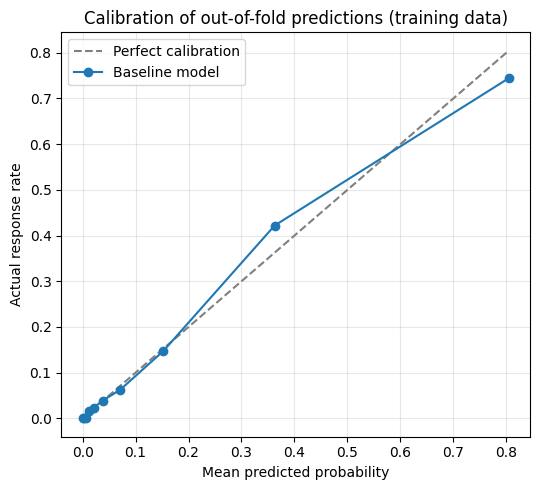

In [10]:
# Calibration: do predicted probabilities match actual response rates? (10 equal-sized groups by predicted probability)
decile = pd.qcut(error_df["oof_proba"], 10, duplicates="drop")
calibration = error_df.groupby(decile, observed=True).agg(
    Customers=(TARGET, "size"),
    Mean_predicted=("oof_proba", "mean"),
    Actual_rate=(TARGET, "mean"),
).reset_index(drop=True)
display(calibration.round(3))

plt.figure(figsize=(5.5, 5))
plt.plot([0, calibration["Mean_predicted"].max()], [0, calibration["Mean_predicted"].max()], "--", color="gray", label="Perfect calibration")
plt.plot(calibration["Mean_predicted"], calibration["Actual_rate"], marker="o", label="Baseline model")
plt.title("Calibration of out-of-fold predictions (training data)")
plt.xlabel("Mean predicted probability")
plt.ylabel("Actual response rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "week10_calibration.png", dpi=150)
plt.show()

#### Data quality audit

Checks that can explain errors or suggest a data fix: duplicated or contradictory rows, missing values, constant columns, and for the continuous features how skewed they are and how many values are extreme.

In [11]:
# Row-level problems
n_duplicate_rows = int(X_train.duplicated().sum())
labeled = train_fit_df[feature_names + [TARGET]]
dup_mask = labeled.duplicated(subset=feature_names, keep=False)
if dup_mask.any():
    label_counts = labeled[dup_mask].groupby(feature_names, sort=False)[TARGET].nunique()
    n_conflicting_groups = int((label_counts > 1).sum())
else:
    n_conflicting_groups = 0
n_missing = int(X_train.isna().sum().sum())
constant_cols = [c for c in feature_names if X_train[c].nunique() <= 1]

print("Duplicated customers (identical predictors):", n_duplicate_rows)
print("Groups of identical customers with different outcomes:", n_conflicting_groups)
print("Missing values in the predictors:", n_missing)
print("Constant predictors:", constant_cols if constant_cols else "none")

# Column-level problems for the continuous features
q01 = X_train[continuous_cols].quantile(0.01)
q99 = X_train[continuous_cols].quantile(0.99)
q1 = X_train[continuous_cols].quantile(0.25)
q3 = X_train[continuous_cols].quantile(0.75)
iqr = q3 - q1
outside_iqr = ((X_train[continuous_cols] < (q1 - 1.5 * iqr)) | (X_train[continuous_cols] > (q3 + 1.5 * iqr))).mean()

audit = pd.DataFrame({
    "Skewness": X_train[continuous_cols].skew(),
    "Share outside 1.5 x IQR": outside_iqr,
    "Minimum": X_train[continuous_cols].min(),
    "99th percentile": q99,
    "Maximum": X_train[continuous_cols].max(),
}).sort_values("Skewness", key=lambda s: s.abs(), ascending=False)
display(audit.round(3))

Duplicated customers (identical predictors): 1
Groups of identical customers with different outcomes: 0
Missing values in the predictors: 0
Constant predictors: none


,Skewness,Share outside 1.5 x IQR,Minimum,99th percentile,Maximum
Income_per_Person,1.789,0.075,-1.224,3.216,3.825
NumStorePurchases,0.768,0.000,-1.788,2.199,2.199
NumWebPurchases,0.680,0.000,-1.524,2.559,2.559
NumDealsPurchases,0.659,0.007,-2.313,2.634,3.644
MntWines,-0.539,0.000,-2.596,1.357,1.440
Total_Spend,-0.372,0.000,-2.341,1.360,1.469
MntGoldProds,-0.364,0.000,-2.441,1.783,1.864
Total_Purchases,0.317,0.000,-1.620,2.013,2.686
Income,0.301,0.002,-2.196,1.988,5.119
NumCatalogPurchases,0.125,0.000,-1.320,1.778,3.031


#### From findings to data treatments

The error analysis suggests which data problems are worth fixing. The treatments tested in Step 3 map to the audit like this:

| Problem found in the data | Treatment tested |
|---|---|
| Extreme values in income and spending features | Cap values at the 1st and 99th percentile (learned on training data only) |
| Strongly skewed spending features (long right tail) | Log transform |
| Responders are rare, so the model finds few of them at the 0.5 cutoff | Oversample the minority class in the training data |

Capping is applied only to continuous features. The earlier all-feature version also clipped binary and one-hot columns, which can erase rare categories.

In [12]:
# Treatment 1 candidates: spend and income features named in the Week 10 experiments, if present
targeted_cols = [c for c in [
    "Income", "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts",
    "MntSweetProducts", "MntGoldProds", "Total_Spend", "Income_per_Person",
] if c in feature_names]

# Treatment 2 candidates: continuous, non-negative, clearly right-skewed features (log needs values >= 0)
skewed_cols = [
    c for c in continuous_cols
    if X_train[c].min() >= 0 and X_train[c].skew() > 1.0
]

print("Targeted capping columns:", targeted_cols)
print("Continuous capping columns:", len(continuous_cols))
print("Log-transform columns:", skewed_cols if skewed_cols else "none (no non-negative, right-skewed features found)")

Targeted capping columns: ['Income', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'Total_Spend', 'Income_per_Person']
Continuous capping columns: 18
Log-transform columns: none (no non-negative, right-skewed features found)


## Step 3: Data improvements

Each treatment is a data change, not a model change. Capping limits and log transforms are **learned on the training data only** and then applied unchanged to the validation and test data, so no information leaks from them. Oversampling is applied to the training data only, because the validation and test data must keep their real response rate.

In [13]:
class DataTreatment(BaseEstimator, TransformerMixin):
    """Caps selected columns at training-set quantiles, then log-transforms selected columns."""

    def __init__(self, cap_cols=None, log_cols=None, lower=0.01, upper=0.99):
        self.cap_cols = cap_cols
        self.log_cols = log_cols
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.cap_cols_ = list(self.cap_cols or [])
        self.log_cols_ = list(self.log_cols or [])
        if self.cap_cols_:
            self.lo_ = X[self.cap_cols_].quantile(self.lower)   # bounds come from the data given to fit
            self.hi_ = X[self.cap_cols_].quantile(self.upper)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        if self.cap_cols_:
            X[self.cap_cols_] = X[self.cap_cols_].clip(lower=self.lo_, upper=self.hi_, axis=1)
        if self.log_cols_:
            X[self.log_cols_] = np.log1p(X[self.log_cols_].clip(lower=0))
        return X


def oversample_minority(X, y, random_state=RANDOM_STATE):
    # Randomly repeat responders until they are as common as non-responders
    y_values = y.to_numpy()
    pos_idx = np.where(y_values == 1)[0]
    neg_idx = np.where(y_values == 0)[0]
    rng = np.random.default_rng(random_state)
    extra = rng.choice(pos_idx, size=len(neg_idx) - len(pos_idx), replace=True)
    keep = np.concatenate([np.arange(len(y_values)), extra])
    return X.iloc[keep].reset_index(drop=True), y.iloc[keep].reset_index(drop=True)


# Registry of treatments. Treatments identical to another one are skipped (for example when no log columns exist).
TREATMENTS = {"Baseline (no data change)": dict(cap=[], log=[], oversample=False)}
TREATMENTS["Cap continuous features"] = dict(cap=continuous_cols, log=[], oversample=False)
if targeted_cols:
    TREATMENTS["Cap spend and income features"] = dict(cap=targeted_cols, log=[], oversample=False)
if skewed_cols:
    TREATMENTS["Log-transform skewed features"] = dict(cap=[], log=skewed_cols, oversample=False)
    TREATMENTS["Cap continuous + log-transform"] = dict(cap=continuous_cols, log=skewed_cols, oversample=False)
TREATMENTS["Oversample responders"] = dict(cap=[], log=[], oversample=True)
TREATMENTS["Cap continuous + oversample"] = dict(cap=continuous_cols, log=[], oversample=True)

print("Treatments to compare:")
for name in TREATMENTS:
    print(" -", name)

Treatments to compare:
 - Baseline (no data change)
 - Cap continuous features
 - Cap spend and income features
 - Oversample responders
 - Cap continuous + oversample


### Compare the treatments with cross-validation on the training data

Every treatment is scored on the same 15 train/validation folds. For each fold the treatment is fit on the fold's training part and scored on its held-out part, and the paired difference from the baseline is recorded. A treatment only counts as an improvement if its average gain is larger than the noise in those paired differences (one standard error).

,PR-AUC (mean),PR-AUC (std),ROC-AUC (mean),PR-AUC change vs baseline,Std. error of change,Folds improved
Treatment,,,,,,
Cap continuous features,0.7237,0.0621,0.9314,0.0044,0.0030,10
Cap continuous + oversample,0.7212,0.0614,0.9298,0.0019,0.0048,8
Baseline (no data change),0.7193,0.0668,0.9292,0.0000,0.0000,0
Cap spend and income features,0.7192,0.0647,0.9295,-0.0001,0.0015,6
Oversample responders,0.7173,0.0650,0.9281,-0.0020,0.0029,6


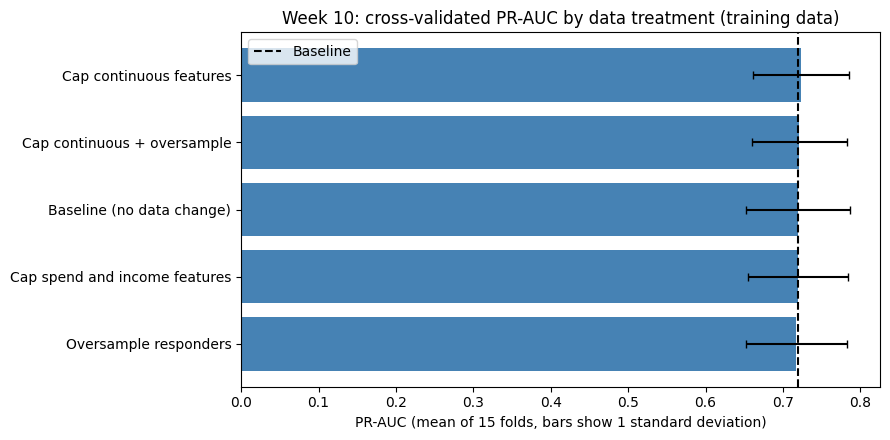

In [14]:
def cross_validate_treatment(cfg):
    # Fold-by-fold PR-AUC and ROC-AUC for one treatment, fitting everything inside each fold
    pr_scores, roc_scores = [], []
    for train_idx, val_idx in cv.split(X_train, y_train):
        X_fold_train, y_fold_train = X_train.iloc[train_idx], y_train.iloc[train_idx]
        X_fold_val, y_fold_val = X_train.iloc[val_idx], y_train.iloc[val_idx]

        treatment = DataTreatment(cap_cols=cfg["cap"], log_cols=cfg["log"]).fit(X_fold_train)
        X_fold_train_t = treatment.transform(X_fold_train)
        X_fold_val_t = treatment.transform(X_fold_val)
        if cfg["oversample"]:
            X_fold_train_t, y_fold_train = oversample_minority(X_fold_train_t, y_fold_train)

        model = clone(final_model).fit(X_fold_train_t, y_fold_train)
        proba = model.predict_proba(X_fold_val_t)[:, 1]
        pr_scores.append(average_precision_score(y_fold_val, proba))
        roc_scores.append(roc_auc_score(y_fold_val, proba))
    return np.array(pr_scores), np.array(roc_scores)


fold_scores = {name: cross_validate_treatment(cfg) for name, cfg in TREATMENTS.items()}

baseline_name = "Baseline (no data change)"
baseline_pr = fold_scores[baseline_name][0]
n_folds = len(baseline_pr)

rows = []
for name, (pr, roc) in fold_scores.items():
    diff = pr - baseline_pr   # paired difference: same folds as the baseline
    rows.append({
        "Treatment": name,
        "PR-AUC (mean)": pr.mean(),
        "PR-AUC (std)": pr.std(ddof=1),
        "ROC-AUC (mean)": roc.mean(),
        "PR-AUC change vs baseline": diff.mean(),
        "Std. error of change": diff.std(ddof=1) / np.sqrt(n_folds),
        "Folds improved": int((diff > 0).sum()),
    })
treatment_results = pd.DataFrame(rows).set_index("Treatment").sort_values("PR-AUC (mean)", ascending=False)
display(treatment_results.round(4))

# Bar chart of mean PR-AUC with one standard deviation across folds
plot_df = treatment_results.sort_values("PR-AUC (mean)")
plt.figure(figsize=(9, 4.5))
plt.barh(plot_df.index, plot_df["PR-AUC (mean)"], xerr=plot_df["PR-AUC (std)"], color="steelblue", capsize=3)
plt.axvline(treatment_results.loc[baseline_name, "PR-AUC (mean)"], color="black", linestyle="--", label="Baseline")
plt.title("Week 10: cross-validated PR-AUC by data treatment (training data)")
plt.xlabel("PR-AUC (mean of 15 folds, bars show 1 standard deviation)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "week10_treatment_comparison.png", dpi=150)
plt.show()

### Select the data treatment

The treatment with the highest average cross-validated PR-AUC is selected. The output states whether its gain over the baseline is larger than one standard error of the paired differences. Repeated cross-validation folds share training data, so the standard error is optimistic, and a gain below one standard error should be read as "no reliable difference".

In [15]:
best_name = treatment_results["PR-AUC (mean)"].idxmax()
best = treatment_results.loc[best_name]
gain = best["PR-AUC change vs baseline"]
se = best["Std. error of change"]

print(f"Selected treatment: {best_name}")
print(f"Mean PR-AUC change vs baseline: {gain:+.4f} (standard error {se:.4f})")
print(f"Folds improved: {int(best['Folds improved'])} of {n_folds}")
if best_name == baseline_name:
    print("No treatment beat the baseline: the original data is kept.")
elif gain > se:
    print("The gain is larger than one standard error: a reliable improvement in cross-validation.")
else:
    print("The gain is within one standard error: not a reliable improvement. The treatment is still carried forward and tested on the validation and test datasets.")

selected_cfg = TREATMENTS[best_name]

Selected treatment: Cap continuous features
Mean PR-AUC change vs baseline: +0.0044 (standard error 0.0030)
Folds improved: 10 of 15
The gain is larger than one standard error: a reliable improvement in cross-validation.


## Step 4: Build the improved datasets for training, validation and test

The selected treatment is fit once on the training dataset and then applied to the training, validation and test datasets. If oversampling is part of the treatment, it is applied to the training dataset only. The new datasets are saved next to the originals.

In [16]:
# Fit the treatment on the training data only, then apply it to all three datasets
final_treatment = DataTreatment(cap_cols=selected_cfg["cap"], log_cols=selected_cfg["log"]).fit(X_train)

X_train_new = final_treatment.transform(X_train)
X_val_new = final_treatment.transform(X_val)
X_test_new = final_treatment.transform(X_test)

# Oversampling changes the training rows only
if selected_cfg["oversample"]:
    X_train_fit_new, y_train_fit_new = oversample_minority(X_train_new, y_train)
else:
    X_train_fit_new, y_train_fit_new = X_train_new, y_train

# Save the new datasets
new_train = X_train_fit_new.assign(**{TARGET: y_train_fit_new.to_numpy()})
new_val = X_val_new.assign(**{TARGET: y_val.to_numpy()})
new_test = X_test_new.assign(**{TARGET: y_test.to_numpy()})
new_train.to_csv(DATA_DIR / "week10_train_improved.csv", index=False)
new_val.to_csv(DATA_DIR / "week10_validation_improved.csv", index=False)
new_test.to_csv(DATA_DIR / "week10_test_improved.csv", index=False)

print("Improved training dataset:", new_train.shape, "| response rate:", round(new_train[TARGET].mean(), 4))
print("Improved validation dataset:", new_val.shape, "| response rate:", round(new_val[TARGET].mean(), 4))
print("Improved test dataset:", new_test.shape, "| response rate:", round(new_test[TARGET].mean(), 4))

# Show what the treatment changed in the columns it touched
changed_cols = sorted(set(selected_cfg["cap"]) | set(selected_cfg["log"]))
if changed_cols:
    change_summary = pd.DataFrame({
        "Mean before": X_train[changed_cols].mean(),
        "Mean after": X_train_new[changed_cols].mean(),
        "Max before": X_train[changed_cols].max(),
        "Max after": X_train_new[changed_cols].max(),
        "Values changed in training data": (X_train[changed_cols] != X_train_new[changed_cols]).sum(),
    })
    display(change_summary.round(3))
else:
    print("The selected treatment does not change any feature values.")

Improved training dataset: (1286, 28) | response rate: 0.1454
Improved validation dataset: (322, 28) | response rate: 0.146
Improved test dataset: (412, 28) | response rate: 0.1529


,Mean before,Mean after,Max before,Max after,Values changed in training data
Age,0.008,0.007,2.460,2.031,18
Income,-0.021,-0.028,5.119,1.988,26
Income_per_Person,-0.028,-0.030,3.825,3.216,26
MntFishProducts,-0.005,-0.005,1.792,1.708,12
MntFruits,-0.004,-0.005,1.923,1.841,13
MntGoldProds,-0.011,-0.011,1.864,1.783,13
MntMeatProducts,-0.018,-0.018,2.085,1.687,19
MntSweetProducts,-0.012,-0.013,1.886,1.822,12
MntWines,-0.026,-0.024,1.440,1.357,18
NumCatalogPurchases,-0.011,-0.015,3.031,1.778,12


## Step 5: Refit the model on the new training data and evaluate

The same model settings are refit on the improved training dataset and compared with the baseline on the training, validation and test datasets. Training and validation scores are computed on the original response rate (without oversampled copies) so the numbers are comparable.

In [17]:
# Refit the Week 9 model settings on the improved training data
improved_model = clone(final_model).fit(X_train_fit_new, y_train_fit_new)

improved_table = pd.DataFrame({
    "Training": score_dataset(improved_model, X_train_new, y_train),
    "Validation": score_dataset(improved_model, X_val_new, y_val),
    "Test": score_dataset(improved_model, X_test_new, y_test),
})

comparison = pd.concat(
    {"Baseline": baseline_table, "Improved data": improved_table, "Change": improved_table - baseline_table},
    axis=1,
)
display(comparison.round(4))

Baseline                    Improved data                     \
                Training Validation    Test      Training Validation    Test   
PR-AUC            0.7664     0.7300  0.6461        0.7691     0.7268  0.6780   
ROC-AUC           0.9445     0.9079  0.8840        0.9464     0.9091  0.8923   
Precision         0.7810     0.7500  0.7179        0.7895     0.7353  0.7179   
Recall            0.5722     0.5106  0.4444        0.5615     0.5319  0.4444   
F1                0.6605     0.6076  0.5490        0.6562     0.6173  0.5490   
Log loss          0.2041     0.2373  0.2847        0.2013     0.2370  0.2748   
Top-40% capture   0.9679     0.9149  0.8571        0.9733     0.9149  0.8571   

                  Change                     
                Training Validation    Test  
PR-AUC            0.0028    -0.0031  0.0319  
ROC-AUC           0.0019     0.0012  0.0083  
Precision         0.0085    -0.0147  0.0000  
Recall           -0.0107     0.0213  0.0000  
F1               -0.0042     0.0097  0.0000  
Log loss         -0.0027    -0.0003 -0.0100  
Top-40% capture   0.0053     0.0000  0.0000

In [18]:
# Is the change on validation and test larger than sampling noise? Paired bootstrap on PR-AUC:
# resample customers with replacement and recompute the difference between the two models each time.
def bootstrap_pr_auc_difference(y_true, proba_improved, proba_baseline, n_boot=2000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].sum() == 0:
            continue
        diffs.append(
            average_precision_score(y_true[idx], proba_improved[idx])
            - average_precision_score(y_true[idx], proba_baseline[idx])
        )
    diffs = np.array(diffs)
    return diffs.mean(), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)


bootstrap_rows = []
for split, (X_b, X_i, y_s) in {
    "Validation": (X_val, X_val_new, y_val),
    "Test": (X_test, X_test_new, y_test),
}.items():
    p_base = baseline_model.predict_proba(X_b)[:, 1]
    p_imp = improved_model.predict_proba(X_i)[:, 1]
    mean_diff, low, high = bootstrap_pr_auc_difference(y_s, p_imp, p_base)
    bootstrap_rows.append({
        "Dataset": split,
        "PR-AUC change": mean_diff,
        "95% interval low": low,
        "95% interval high": high,
        "Interval excludes zero": bool(low > 0 or high < 0),
    })
bootstrap_table = pd.DataFrame(bootstrap_rows).set_index("Dataset")
display(bootstrap_table.round(4))

,PR-AUC change,95% interval low,95% interval high,Interval excludes zero
Dataset,,,,
Validation,-0.0030,-0.0214,0.0111,False
Test,0.0308,0.0009,0.0819,True


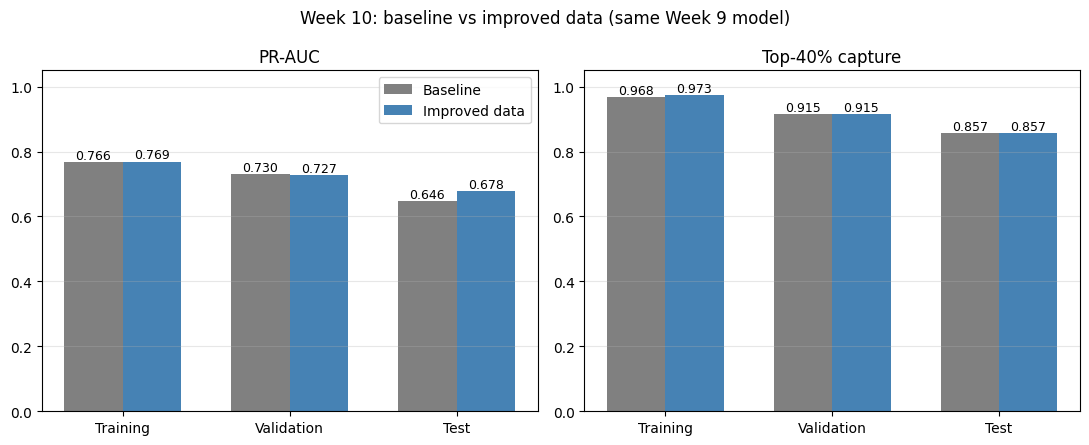

In [19]:
# Figure: PR-AUC and top-40% capture for the baseline and improved data on all three datasets
splits = ["Training", "Validation", "Test"]
x = np.arange(len(splits))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, metric in zip(axes, ["PR-AUC", "Top-40% capture"]):
    base_vals = [baseline_table.loc[metric, s] for s in splits]
    imp_vals = [improved_table.loc[metric, s] for s in splits]
    bars_a = ax.bar(x - width / 2, base_vals, width, label="Baseline", color="gray")
    bars_b = ax.bar(x + width / 2, imp_vals, width, label="Improved data", color="steelblue")
    for bar in list(bars_a) + list(bars_b):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f"{bar.get_height():.3f}", ha="center", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(splits)
    ax.set_ylim(0, 1.05)
    ax.set_title(metric)
    ax.grid(axis="y", alpha=0.3)
axes[0].legend()
fig.suptitle("Week 10: baseline vs improved data (same Week 9 model)")
plt.tight_layout()
plt.savefig(FIG_DIR / "week10_train_val_test.png", dpi=150)
plt.show()

In [20]:
# Save the Week 10 result: the same model, its treatment and the predictor list
joblib.dump(
    {
        "model": improved_model,
        "treatment": final_treatment,
        "treatment_name": best_name,
        "oversample_training": selected_cfg["oversample"],
        "features": feature_names,
        "name": f"Week 10 {model_name} with data treatment: {best_name}",
    },
    MODEL_DIR / "week10_final_model.joblib",
)

# Plain-language summary generated from the results above
print("WEEK 10 SUMMARY")
print(f"Model held constant: {model_name}")
print(f"Selected data treatment: {best_name}")
for split in splits:
    print(
        f"{split}: PR-AUC {baseline_table.loc['PR-AUC', split]:.4f} -> {improved_table.loc['PR-AUC', split]:.4f}, "
        f"top-40% capture {baseline_table.loc['Top-40% capture', split]:.3f} -> {improved_table.loc['Top-40% capture', split]:.3f}"
    )
for split, row in bootstrap_table.iterrows():
    status = "reliable (interval excludes zero)" if row["Interval excludes zero"] else "not reliable (interval includes zero)"
    print(f"{split} PR-AUC change {row['PR-AUC change']:+.4f}, 95% interval [{row['95% interval low']:+.4f}, {row['95% interval high']:+.4f}]: {status}")

WEEK 10 SUMMARY
Model held constant: W6 Logistic regression
Selected data treatment: Cap continuous features
Training: PR-AUC 0.7664 -> 0.7691, top-40% capture 0.968 -> 0.973
Validation: PR-AUC 0.7300 -> 0.7268, top-40% capture 0.915 -> 0.915
Test: PR-AUC 0.6461 -> 0.6780, top-40% capture 0.857 -> 0.857
Validation PR-AUC change -0.0030, 95% interval [-0.0214, +0.0111]: not reliable (interval includes zero)
Test PR-AUC change +0.0308, 95% interval [+0.0009, +0.0819]: reliable (interval excludes zero)


## Round 2: targeted features for the customers the model gets wrong

The error analysis showed two groups the model handles poorly. Missed responders have no previous campaign acceptance and average income, so the model has little signal for them. False alarms are engaged, recent, high-spending customers who still did not respond. Round 2 adds two kinds of features aimed at these groups, on top of the capping selected in Round 1:

- **No-acceptance flag:** 1 if the customer never accepted a previous campaign.
- **Interactions:** previous acceptances x recency and total spend x recency, which separate engaged recent customers from customers who only spend a lot.

Each candidate is tested with the same 15 cross-validation folds. A candidate is adopted only if it beats Round 1 by more than one standard error of the paired differences. All candidates are reported, including those that do not help.

In [21]:
# Features aimed at missed responders and false alarms. All values the features depend on are learned from training data only.
needed = ["Total_Prev_Accepted", "Recency", "Total_Spend"]
assert all(c in feature_names for c in needed), "A required column is missing"


class FeatureAdder(BaseEstimator, TransformerMixin):
    """Adds a 'never accepted a previous campaign' flag and two interaction features."""

    def __init__(self, flag=False, interactions=False):
        self.flag = flag
        self.interactions = interactions

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        # The column is standardized, so "never accepted" is its lowest value in the training data
        self.no_accept_value_ = X["Total_Prev_Accepted"].min()
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        if self.flag:
            X["No_Prev_Accepted"] = (X["Total_Prev_Accepted"] <= self.no_accept_value_ + 1e-9).astype(int)
        if self.interactions:
            X["PrevAccepted_x_Recency"] = X["Total_Prev_Accepted"] * X["Recency"]
            X["Spend_x_Recency"] = X["Total_Spend"] * X["Recency"]
        return X


# Check what "never accepted" looks like and how the response rate changes with previous acceptances
accept_check = (
    pd.DataFrame({"Total_Prev_Accepted": X_train["Total_Prev_Accepted"].round(3), "Response": y_train})
    .groupby("Total_Prev_Accepted")["Response"]
    .agg(["size", "mean"])
    .rename(columns={"size": "Customers", "mean": "Response rate"})
)
display(accept_check.round(3))

,Customers,Response rate
Total_Prev_Accepted,,
-0.442,1024,0.072
0.995,184,0.337
2.432,47,0.532
3.869,24,0.833
5.306,7,0.857


In [22]:
def cross_validate_features(flag, interactions):
    # Fold-by-fold scores for: cap (Round 1 treatment) -> add features -> fit the same model
    pr_scores, roc_scores = [], []
    for train_idx, val_idx in cv.split(X_train, y_train):
        X_fold_train, y_fold_train = X_train.iloc[train_idx], y_train.iloc[train_idx]
        X_fold_val, y_fold_val = X_train.iloc[val_idx], y_train.iloc[val_idx]

        capper = DataTreatment(cap_cols=selected_cfg["cap"], log_cols=selected_cfg["log"]).fit(X_fold_train)
        X_fold_train_c, X_fold_val_c = capper.transform(X_fold_train), capper.transform(X_fold_val)

        adder = FeatureAdder(flag=flag, interactions=interactions).fit(X_fold_train_c)
        X_fold_train_f, X_fold_val_f = adder.transform(X_fold_train_c), adder.transform(X_fold_val_c)

        model = clone(final_model).fit(X_fold_train_f, y_fold_train)
        proba = model.predict_proba(X_fold_val_f)[:, 1]
        pr_scores.append(average_precision_score(y_fold_val, proba))
        roc_scores.append(roc_auc_score(y_fold_val, proba))
    return np.array(pr_scores), np.array(roc_scores)


candidates = {
    "Cap + no-acceptance flag": (True, False),
    "Cap + two interactions": (False, True),
    "Cap + flag + interactions": (True, True),
}
round1_label = f"Round 1: {best_name}"
round1_pr = fold_scores[best_name][0]

all_scores = {
    baseline_name: fold_scores[baseline_name],
    round1_label: fold_scores[best_name],
    **{name: cross_validate_features(*args) for name, args in candidates.items()},
}

rows = []
for name, (pr, roc) in all_scores.items():
    diff_baseline = pr - baseline_pr
    diff_round1 = pr - round1_pr
    rows.append({
        "Version": name,
        "PR-AUC (mean)": pr.mean(),
        "PR-AUC (std)": pr.std(ddof=1),
        "ROC-AUC (mean)": roc.mean(),
        "Change vs baseline": diff_baseline.mean(),
        "Change vs Round 1": diff_round1.mean(),
        "Std. error vs Round 1": diff_round1.std(ddof=1) / np.sqrt(len(diff_round1)),
        "Folds better than Round 1": int((diff_round1 > 0).sum()),
    })
round2_results = pd.DataFrame(rows).set_index("Version")
display(round2_results.round(4))

,PR-AUC (mean),PR-AUC (std),ROC-AUC (mean),Change vs baseline,Change vs Round 1,Std. error vs Round 1,Folds better than Round 1
Version,,,,,,,
Baseline (no data change),0.7193,0.0668,0.9292,0.0000,-0.0044,0.0030,5
Round 1: Cap continuous features,0.7237,0.0621,0.9314,0.0044,0.0000,0.0000,0
Cap + no-acceptance flag,0.7188,0.0672,0.9309,-0.0005,-0.0049,0.0032,5
Cap + two interactions,0.7228,0.0632,0.9321,0.0035,-0.0010,0.0023,7
Cap + flag + interactions,0.7212,0.0679,0.9319,0.0019,-0.0026,0.0038,9


In [23]:
# Best new candidate and whether it clearly beats Round 1 (gain larger than one paired standard error)
cand_best = round2_results.loc[list(candidates), "PR-AUC (mean)"].idxmax()
gain = round2_results.loc[cand_best, "Change vs Round 1"]
se = round2_results.loc[cand_best, "Std. error vs Round 1"]
adopt_round2 = bool(gain > 0 and gain > se)

print(f"Best Round 2 candidate: {cand_best}")
print(f"PR-AUC change vs Round 1: {gain:+.4f} (standard error {se:.4f})")
print("Decision:", "adopt the candidate" if adopt_round2 else "keep Round 1: the candidate does not clearly beat it")

Best Round 2 candidate: Cap + two interactions
PR-AUC change vs Round 1: -0.0010 (standard error 0.0023)
Decision: keep Round 1: the candidate does not clearly beat it


In [24]:
round2_table = None
if adopt_round2:
    flag, interactions = candidates[cand_best]

    # Fit capping, then the feature adder, on the training data only; apply to all three datasets
    capper2 = DataTreatment(cap_cols=selected_cfg["cap"], log_cols=selected_cfg["log"]).fit(X_train)
    X_train_c, X_val_c, X_test_c = (capper2.transform(d) for d in (X_train, X_val, X_test))
    adder2 = FeatureAdder(flag=flag, interactions=interactions).fit(X_train_c)
    X_train_r2, X_val_r2, X_test_r2 = (adder2.transform(d) for d in (X_train_c, X_val_c, X_test_c))

    # Save the Round 2 datasets
    X_train_r2.assign(**{TARGET: y_train.to_numpy()}).to_csv(DATA_DIR / "week10_train_improved_v2.csv", index=False)
    X_val_r2.assign(**{TARGET: y_val.to_numpy()}).to_csv(DATA_DIR / "week10_validation_improved_v2.csv", index=False)
    X_test_r2.assign(**{TARGET: y_test.to_numpy()}).to_csv(DATA_DIR / "week10_test_improved_v2.csv", index=False)
    print("New features:", [c for c in X_train_r2.columns if c not in feature_names])
    print("Round 2 datasets:", X_train_r2.shape, X_val_r2.shape, X_test_r2.shape)

    # Refit the same model on the Round 2 training data and score all three datasets
    round2_model = clone(final_model).fit(X_train_r2, y_train)
    round2_table = pd.DataFrame({
        "Training": score_dataset(round2_model, X_train_r2, y_train),
        "Validation": score_dataset(round2_model, X_val_r2, y_val),
        "Test": score_dataset(round2_model, X_test_r2, y_test),
    })
    display(pd.concat({"Baseline": baseline_table, "Round 1": improved_table, "Round 2": round2_table}, axis=1).round(4))

    # Paired bootstrap of the PR-AUC change on validation and test, vs the baseline and vs Round 1
    boot_rows = []
    for split, X_b, X_1, X_2, y_s in [
        ("Validation", X_val, X_val_new, X_val_r2, y_val),
        ("Test", X_test, X_test_new, X_test_r2, y_test),
    ]:
        p_base = baseline_model.predict_proba(X_b)[:, 1]
        p_r1 = improved_model.predict_proba(X_1)[:, 1]
        p_r2 = round2_model.predict_proba(X_2)[:, 1]
        for label, p_ref in [("vs baseline", p_base), ("vs Round 1", p_r1)]:
            mean_diff, low, high = bootstrap_pr_auc_difference(y_s, p_r2, p_ref)
            boot_rows.append({"Dataset": split, "Comparison": label, "PR-AUC change": mean_diff,
                              "95% interval low": low, "95% interval high": high,
                              "Interval excludes zero": bool(low > 0 or high < 0)})
    display(pd.DataFrame(boot_rows).round(4))

    joblib.dump(
        {"model": round2_model, "capper": capper2, "feature_adder": adder2, "treatment_name": cand_best,
         "features": list(X_train_r2.columns)},
        MODEL_DIR / "week10_final_model_v2.joblib",
    )
else:
    print("Round 2 not adopted: no Round 2 datasets or model were created.")

Round 2 not adopted: no Round 2 datasets or model were created.


In [25]:
print("ROUND 2 SUMMARY")
print(f"Best candidate: {cand_best} ({gain:+.4f} PR-AUC vs Round 1, standard error {se:.4f})")
if adopt_round2:
    for split in ["Training", "Validation", "Test"]:
        print(
            f"{split}: PR-AUC {baseline_table.loc['PR-AUC', split]:.4f} (baseline) -> "
            f"{improved_table.loc['PR-AUC', split]:.4f} (Round 1) -> {round2_table.loc['PR-AUC', split]:.4f} (Round 2)"
        )
else:
    print("Round 2 did not clearly beat Round 1, so the Round 1 data treatment stays final.")

ROUND 2 SUMMARY
Best candidate: Cap + two interactions (-0.0010 PR-AUC vs Round 1, standard error 0.0023)
Round 2 did not clearly beat Round 1, so the Round 1 data treatment stays final.


## WEEK 10 - END